In [71]:
import pandas as pd
import numpy as np
import seaborn as sns

In [83]:
df_train = pd.read_csv('data_train.csv')
df_val = pd.read_csv('data_validation.csv')
df_test = pd.read_csv('data_test.csv')
df_prep = pd.read_csv('data_prepped.csv')

y_train = np.loadtxt('y_train.csv')
y_val = np.loadtxt('y_val.csv')
y_test = np.loadtxt('y_test.csv')

In [96]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

In [85]:
#only pick the numeric fields and pu tinto numpy array
base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']
X_train = df_train[base].values
X_train

array([[ 148.,    4.,   33.,   24., 1385.],
       [ 132.,    4.,   32.,   25., 2031.],
       [ 148.,    4.,   37.,   28.,  640.],
       ...,
       [ 285.,    6.,   22.,   17.,  549.],
       [ 563.,   12.,   21.,   13.,   86.],
       [ 200.,    4.,   31.,   22.,  873.]], shape=(7150, 5))

In [86]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

The following will produce NaN in the matrix because some value in the feature matrix X_train are NULL

In [87]:
w0, w = train_linear_regression(X_train, y_train)
w0, w

(np.float64(nan), array([nan, nan, nan, nan, nan]))

In [88]:
X_train = df_train[base].fillna(0).values
w0, w = train_linear_regression(X_train, y_train)
w0

np.float64(7.927257388070037)

In [89]:
y_pred = w0+X_train.dot(w)
y_pred

array([ 9.54792783,  9.38733977,  9.67197758, ..., 10.30423015,
       11.9778914 ,  9.99863111], shape=(7150,))

<Axes: ylabel='Count'>

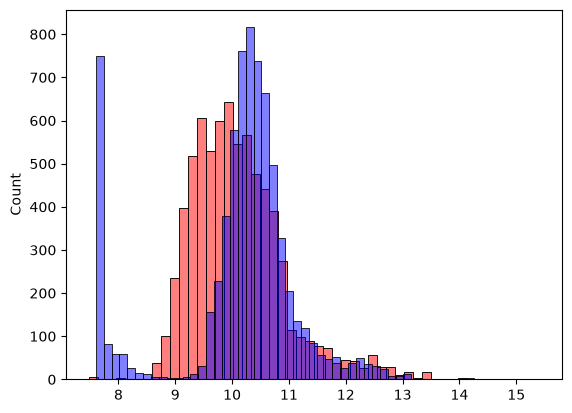

In [90]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

Now calculate the RMSE. Objection value to determine how good the model is at predicting

In [91]:
def rmse(y_train, y_pred):
    error = (y_train-y_pred) ** 2
    mse = error.mean()
    return np.sqrt(mse)

In [92]:
rmse(y_train, y_pred)

np.float64(0.7554192603920132)

Now runmodel against validaton dataset

<Axes: ylabel='Count'>

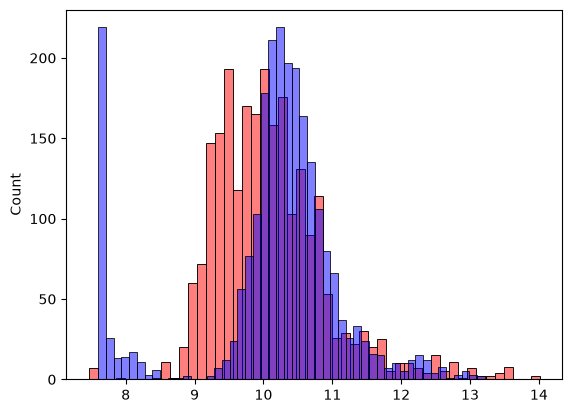

In [95]:
sns.histplot(y_pred_val, color='red', alpha=0.5, bins=50)
sns.histplot(y_val, color='blue', alpha=0.5, bins=50)

In [94]:
X_val = df_val[base].fillna(0).values
y_pred_val = w0+X_val.dot(w)

rmse(y_val,y_pred_val)

np.float64(0.7616530991301627)